In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import torchvision.models as models

weights = models.VGG19_Weights.DEFAULT
vgg = models.vgg19(weights=weights).features.eval()

print("Pretrained VGG19 model loaded successfully!")

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:04<00:00, 131MB/s]


Pretrained VGG19 model loaded successfully!


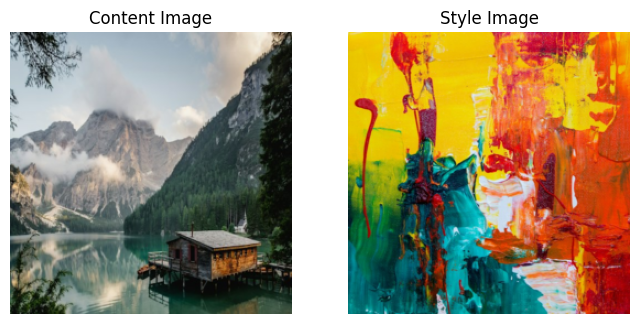

In [3]:
import torch
import torch.nn.functional as F
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vgg = vgg.to(device)

def load_image(url, size=256):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    image = Image.open(BytesIO(response.content)).convert("RGB")
    transform = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor()
    ])
    return transform(image).unsqueeze(0).to(device)

content_url = "https://images.unsplash.com/photo-1470770841072-f978cf4d019e?w=512"
style_url = "https://images.unsplash.com/photo-1541961017774-22349e4a1262?w=512"

content_img = load_image(content_url)
style_img = load_image(style_url)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(content_img.squeeze(0).cpu().permute(1, 2, 0))
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(style_img.squeeze(0).cpu().permute(1, 2, 0))
plt.title("Style Image")
plt.axis("off")

plt.show()

In [4]:
# VGG19 feature layers
content_layers = ["21"]
style_layers = ["0", "5", "10", "19", "28"]

def get_features(image, model):
    features = {}
    x = image

    for name, layer in model._modules.items():
        x = layer(x)
        if name in content_layers or name in style_layers:
            features[name] = x

    return features

def gram_matrix(tensor):
    batch, channels, height, width = tensor.size()
    features = tensor.view(channels, height * width)
    gram = torch.mm(features, features.t())
    return gram / (channels * height * width)

content_features = get_features(content_img, vgg)
style_features = get_features(style_img, vgg)

style_grams = {
    layer: gram_matrix(style_features[layer])
    for layer in style_layers
}

print("Content and style features extracted successfully!")

Content and style features extracted successfully!


In [6]:
# Start with a copy of the content image
target = content_img.clone().requires_grad_(True)

# Normalize images as expected by pretrained VGG19
mean = torch.tensor([0.485, 0.456, 0.406],
                    device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225],
                   device=device).view(1, 3, 1, 1)

def normalize_image(image):
    return (image - mean) / std

# Extract static features inside a no_grad block to prevent keeping graph history
with torch.no_grad():
    content_features = get_features(normalize_image(content_img), vgg)
    style_features = get_features(normalize_image(style_img), vgg)

style_grams = {
    layer: gram_matrix(style_features[layer])
    for layer in style_layers
}

optimizer = torch.optim.Adam([target], lr=0.02)

content_weight = 1
style_weight = 1e6

for step in range(301):
    optimizer.zero_grad()

    target_features = get_features(normalize_image(target), vgg)

    content_loss = F.mse_loss(
        target_features["21"], content_features["21"]
    )

    style_loss = 0
    for layer in style_layers:
        target_gram = gram_matrix(target_features[layer])
        style_loss += F.mse_loss(target_gram, style_grams[layer])

    total_loss = content_weight * content_loss + style_weight * style_loss
    total_loss.backward()
    optimizer.step()

    with torch.no_grad():
        target.clamp_(0, 1)

    if step % 50 == 0:
        print(f"Step {step}: Loss = {total_loss.item():.4f}")

print("Neural Style Transfer completed!")

Step 0: Loss = 642.4013
Step 50: Loss = 37.7237
Step 100: Loss = 28.1685
Step 150: Loss = 24.0158
Step 200: Loss = 21.7018
Step 250: Loss = 19.3508
Step 300: Loss = 16.7299
Neural Style Transfer completed!


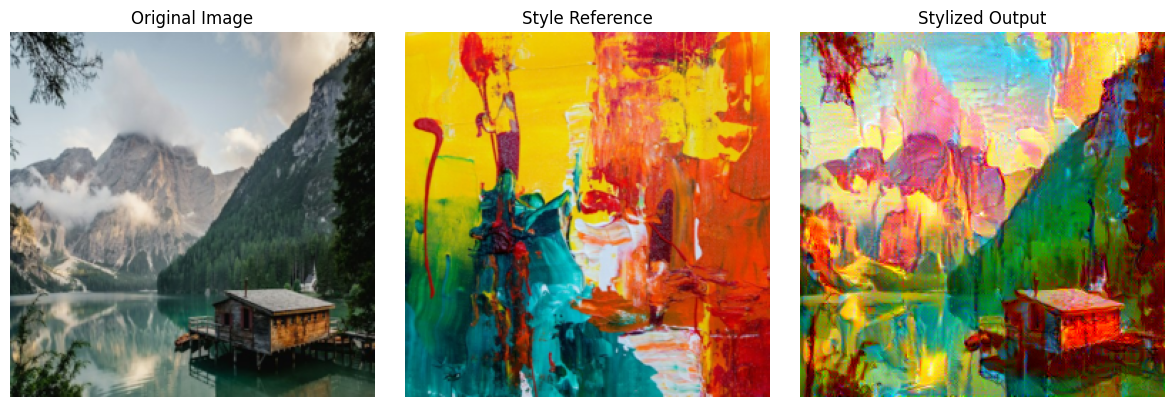

Result saved successfully!


In [7]:
output = target.detach().squeeze(0).cpu().permute(1, 2, 0).numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(content_img.squeeze(0).cpu().permute(1, 2, 0))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(style_img.squeeze(0).cpu().permute(1, 2, 0))
plt.title("Style Reference")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(output)
plt.title("Stylized Output")
plt.axis("off")

plt.tight_layout()
plt.savefig("Task5_Neural_Style_Transfer_Result.png", dpi=150)
plt.show()

print("Result saved successfully!")